# Group Work AS 2026: ESG, Stock Returns and Machine Learning

**Course:** EAIF: AI for Finance

This notebook is the starting point for the group assignment. It loads the data, explores it, works through **one** forecasting model end to end and shows **one** backtest pattern. Everything after Section 4 is your work.

## Dataset

Simulated by the course for this assignment (licence CC BY 4.0, EAIF course). Five data files and a README, loaded from the course GitHub repository; the data dictionary handed out with the assignment describes every column.

> ### Simulated data with real problems
> There are no real firms behind these rows. The generator planted a small number of data problems of the kind real financial data has: things that are not what they seem, values that are known too early or too late, samples that are not what you think they are. **Finding and treating them is task (a) and is graded.** The generator also planted one genuine relationship between ESG scores and returns; whether you find it, and only it, is task (c).
>
> Your memo must still contain a section on what a real-data version of your analysis would need beyond what you did here. That section is graded (see the rubric below).

## How to use this notebook

1. Make a copy (File, then "Save a copy in Drive").
2. Run the given cells in order and read the comments.
3. Add your own cells for the tasks in Section 5. Keep the given cells so the grader can follow the pipeline.
4. Submit the completed notebook together with the memo and the slides.


# Assignment brief

**Deadlines**

| What | When |
|---|---|
| Memo (PDF), notebook (`.ipynb`), `results.json` and peer evaluation, via Moodle | Friday, 27 November 2026, 23:59 |
| Slides (PDF), via Moodle or by email to the lecturers | Monday, 7 December 2026, 23:59 |
| Presentations, 10 minutes per group plus questions | Tuesday, 8 December 2026 |

**Group size:** 3 to 4 students. Assign roles at the first meeting and name them in the memo: a **data lead** (pipeline, audit), a **modelling lead** (models, cross-validation, tuning), an **analysis lead** (premium, backtest, figures, tables) and a **writing lead** (memo, slides). Everyone must be able to explain every cell.

**Deliverables**

| Deliverable | Format | Length |
|---|---|---|
| Notebook | `.ipynb`, runs top to bottom in Colab without errors | as needed |
| Memo | PDF, addressed to an investment committee | 3 pages plus appendix |
| Slides | PDF, for a 10-minute presentation | at most 8 slides |
| `results.json` | `.json`, written by the notebook's `write_results` helper | one file |

**Rubric (100 points)**

| Criterion | Points | What the grader looks for |
|---|---|---|
| Pipeline and data audit (task a) | 20 | 5 for a leakage-free formation panel; 15 for the audit table, graded against the list of planted problems |
| Model comparison (task b) | 20 | linear baseline vs tree ensemble, selection on cross-validation, test reported once, next to a naive baseline |
| Where does ESG pay (task c) | 15 | 8 for finding the cell where the premium exists and only that cell; 4 for honest uncertainty; 3 for the point-in-time vs restated comparison |
| Backtest with costs and an ESG floor (task d) | 15 | formed after publication, held twelve months, costs charged, the cost of the floor shown, bootstrap of the difference to the benchmark |
| Memo and slides (task e) | 15 | clear question, clear answer, figures with labelled axes and units, no overclaiming; 10 minutes |
| What would change with real data | 15 | 5 for the list (what remains after your audit), 10 for which of your conclusions would survive and why |

Tasks (a) to (d) are graded from the notebook and the memo together: the memo states the result, the notebook must show how it was produced. A result in the memo that the notebook does not reproduce earns no points.

**Given / Your work**

| | Sections | Status |
|---|---|---|
| Given | 1 Setup and loading, 2 Exploration, 3 One worked model, 4 One backtest pattern, 6 the submission helper | run and read; do not delete |
| Your work | 5 Tasks (a) to (e), and the values in 6 | new cells below Section 5, the submission file filled in, plus the memo and the slides |


# 1. Setup and data loading (given)

In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

plt.rcParams['figure.figsize'] = (10, 6)
sns.set_style("whitegrid")


In [13]:
# Five data files, simulated by the course. Licence: CC BY 4.0 (EAIF course); cite them in the memo.
DATA_URL = os.environ.get("ESG2026_DATA", "https://raw.githubusercontent.com/umatter/EDFB/main/data/esg2026/")

panel    = pd.read_csv(DATA_URL + "firm_year_panel.csv")       # firm x fiscal year: fundamentals, point-in-time ESG scores
restated = pd.read_csv(DATA_URL + "esg_scores_restated.csv")   # firm x fiscal year: ESG scores as downloaded today
returns  = pd.read_csv(DATA_URL + "stock_returns_monthly.csv") # firm x month: total return, percent
factors  = pd.read_csv(DATA_URL + "factors_monthly.csv")       # month: risk-free rate, market, size, industry factors, percent
universe = pd.read_csv(DATA_URL + "universe_current.csv")      # firms in the universe at the end of the last year

for name, df in [("panel", panel), ("restated", restated), ("returns", returns), ("factors", factors), ("universe", universe)]:
    print(f"{name:<9} {df.shape[0]:>8,} rows x {df.shape[1]:>2} columns")

# Join keys: panel and restated on (Company_ID, Year); returns and factors on Month; universe on Company_ID.
# Publication_Date says when the fiscal-year row became public. Nothing in that row is known before that date.
print("\nPublication dates for fiscal year 2020 (first rows):")
print(panel.loc[panel["Year"] == 2020, ["Company_ID", "Year", "Publication_Date"]].head(3).to_string(index=False))
print("Latest publication date in the panel:", pd.to_datetime(panel["Publication_Date"]).dt.strftime("%m-%d").max(),
      "(so a portfolio formed on 1 July of the following year can use the whole fiscal year)")
panel.head()


panel       14,250 rows x 18 columns
restated    14,250 rows x  6 columns
returns    171,764 rows x  3 columns
factors        168 rows x 13 columns
universe       987 rows x  4 columns

Publication dates for fiscal year 2020 (first rows):
 Company_ID  Year Publication_Date
          1  2020       2021-05-02
          2  2020       2021-05-15
          4  2020       2021-05-27
Latest publication date in the panel: 05-30 (so a portfolio formed on 1 July of the following year can use the whole fiscal year)


,Company_ID,Company_Name,Industry,Region,Year,Publication_Date,Revenue,Profit_Margin,Market_Cap,Growth_Rate,ESG_Score,Environmental_Score,Social_Score,Governance_Score,Carbon_Emissions,Water_Usage,Energy_Consumption,Analyst_Outlook
0,1,Firm_1,Finance,Asia,2012,2013-05-02,2308.8,20.11,3842.5,NaN,50.9,53.4,45.4,53.2,4204.9,9718.2,154794.3,5
1,1,Firm_1,Finance,Asia,2013,2014-05-02,2548.0,23.06,4998.1,10.36,49.5,51.2,38.3,55.5,18439.8,12106.7,155303.4,5
2,1,Firm_1,Finance,Asia,2014,2015-05-02,2557.1,22.32,7750.5,0.36,48.0,51.7,40.2,51.3,24284.5,8499.5,163112.5,4
3,1,Firm_1,Finance,Asia,2015,2016-05-02,2731.1,22.93,9102.9,6.81,50.3,58.3,39.9,53.3,NaN,NaN,NaN,5
4,1,Firm_1,Finance,Asia,2016,2017-05-02,2712.0,21.48,8609.9,-0.70,52.6,66.6,45.2,51.5,9041.8,5382.5,95567.1,1


In [14]:
import numpy as np
import pandas as pd

# 1. Inspect Missing Values in the panel
print("=== Missing Values Summary ===")
missing = panel.isna().sum()
missing_pct = 100 * missing / len(panel)
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage (%)': missing_pct.round(2)})
display(missing_df[missing_df['Missing Count'] > 0])

# 2. Investigate the 'second cluster' in Revenue
# Let's see the distribution of Revenue and look for the threshold of the second cluster
print("\n=== Revenue Distribution Quantiles ===")
display(panel['Revenue'].quantile([0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

# Let's inspect the smallest revenues to see if there is a separate micro-firm cluster
small_revenue_firms = panel[panel['Revenue'] < 100]
print(f"\nNumber of rows with Revenue < 100: {len(small_revenue_firms)}")
if len(small_revenue_firms) > 0:
    print("Sample of firms with very low revenue:")
    display(small_revenue_firms[['Company_ID', 'Company_Name', 'Revenue', 'Industry', 'Region']].head(10))

# 3. Check for potential outliers in other key columns (Market Cap, Profit Margin, ESG Scores)
print("\n=== Key Columns Outliers & Range Check ===")
for col in ['Profit_Margin', 'Market_Cap', 'ESG_Score', 'Environmental_Score', 'Social_Score', 'Governance_Score']:
    col_min = panel[col].min()
    col_max = panel[col].max()
    print(f"{col:<20} | Min: {col_min:>8.2f} | Max: {col_max:>8.2f}")

# Let's check for extreme Profit Margins (e.g., extremely negative or over 100%)
outlier_margins = panel[(panel['Profit_Margin'] < -100) | (panel['Profit_Margin'] > 100)]
print(f"\nRows with extreme Profit Margin (< -100% or > 100%): {len(outlier_margins)}")
if len(outlier_margins) > 0:
    display(outlier_margins[['Company_ID', 'Company_Name', 'Year', 'Profit_Margin']].head(10))

=== Missing Values Summary ===


,Missing Count,Percentage (%)
Growth_Rate,1376,9.66
Carbon_Emissions,1887,13.24
Water_Usage,1887,13.24
Energy_Consumption,1887,13.24



=== Revenue Distribution Quantiles ===


,Revenue
0.01,155.586
0.05,330.025
0.10,496.700
0.25,977.500
0.50,2405.700
0.75,6062.675
0.90,14570.830
0.95,29396.230
0.99,1722999.180



Number of rows with Revenue < 100: 72
Sample of firms with very low revenue:


,Company_ID,Company_Name,Revenue,Industry,Region
2668,224,Firm_224,39.5,Healthcare,North America
2669,224,Firm_224,44.1,Healthcare,North America
2670,224,Firm_224,50.6,Healthcare,North America
2671,224,Firm_224,59.0,Healthcare,North America
2672,224,Firm_224,65.9,Healthcare,North America
2673,224,Firm_224,71.6,Healthcare,North America
2674,224,Firm_224,78.7,Healthcare,North America
2675,224,Firm_224,75.3,Healthcare,North America
2676,224,Firm_224,81.0,Healthcare,North America
2680,224,Firm_224,98.9,Healthcare,North America



=== Key Columns Outliers & Range Check ===
Profit_Margin        | Min:    -5.47 | Max:    29.34
Market_Cap           | Min:    22.60 | Max: 157136175.30
ESG_Score            | Min:     4.60 | Max:    96.80
Environmental_Score  | Min:     0.00 | Max:   100.00
Social_Score         | Min:     0.00 | Max:   100.00
Governance_Score     | Min:     0.00 | Max:   100.00

Rows with extreme Profit Margin (< -100% or > 100%): 0


In [18]:
import pandas as pd

# Calculate unique firms in the panel per year
firms_panel = panel.groupby('Year')['Company_ID'].nunique()

# For returns, we need to extract the year from the Month column
returns['Year'] = pd.to_datetime(returns['Month']).dt.year
firms_returns = returns.groupby('Year')['Company_ID'].nunique()

# Merge to compare them side-by-side
audit_firms = pd.DataFrame({
    'Firms in Panel': firms_panel,
    'Firms in Returns': firms_returns
})

print("=== Unique Firms per Year Comparison ===")
display(audit_firms)

# Let's see if the 'universe' file matches the last year's count
print(f"\nFirms in current universe file: {universe['Company_ID'].nunique()}")


=== Unique Firms per Year Comparison ===


,Firms in Panel,Firms in Returns
Year,,
2012,1000,1000
2013,1028,1028
2014,1038,1068
2015,1039,1068
2016,1030,1066
2017,1023,1056
2018,1019,1050
2019,1010,1042
2020,1016,1037



Firms in current universe file: 987


# 2. Exploration (given)

Look before you model. Three things to check in every panel: what is missing and where, how sizes are distributed, and how many firms there are in each year. Nothing below is cleaned. Write down every oddity you notice; each one is a line in your audit table (task a).


Missing values per column (panel):
Growth_Rate           1376
Carbon_Emissions      1887
Water_Usage           1887
Energy_Consumption    1887
dtype: int64

Summary statistics (panel):


,Company_ID,Year,Revenue,Profit_Margin,Market_Cap,Growth_Rate,ESG_Score,Environmental_Score,Social_Score,Governance_Score,Carbon_Emissions,Water_Usage,Energy_Consumption,Analyst_Outlook
count,14250.00,14250.00,14250.00,14250.00,1.425000e+04,12874.00,14250.00,14250.00,14250.00,14250.00,1.236300e+04,1.236300e+04,1.236300e+04,14250.00
mean,606.95,2018.47,117805.30,10.93,2.132049e+05,5.18,54.94,55.34,54.77,54.18,2.496227e+06,1.699071e+06,1.573647e+07,3.00
std,358.78,4.02,1496076.42,5.48,2.721234e+06,10.29,11.37,17.35,18.24,18.07,1.208622e+07,1.033246e+07,7.123784e+07,1.42
min,1.00,2012.00,30.30,-5.47,2.260000e+01,-30.97,4.60,0.00,0.00,0.00,2.381000e+02,1.895000e+02,1.801600e+03,1.00
25%,296.00,2015.00,977.50,6.90,1.869750e+03,-1.87,47.20,43.70,42.10,41.70,3.656025e+04,2.587365e+04,3.783915e+05,2.00
50%,601.00,2018.00,2405.70,10.58,4.882150e+03,4.82,55.10,55.25,54.50,54.30,1.882373e+05,1.049367e+05,1.594587e+06,3.00
75%,901.00,2022.00,6062.68,14.87,1.346420e+04,11.79,62.90,67.10,67.10,66.70,9.916322e+05,5.172482e+05,7.265620e+06,4.00
max,1376.00,2025.00,63993116.10,29.34,1.571362e+08,61.11,96.80,100.00,100.00,100.00,3.952938e+08,4.651417e+08,2.295873e+09,5.00


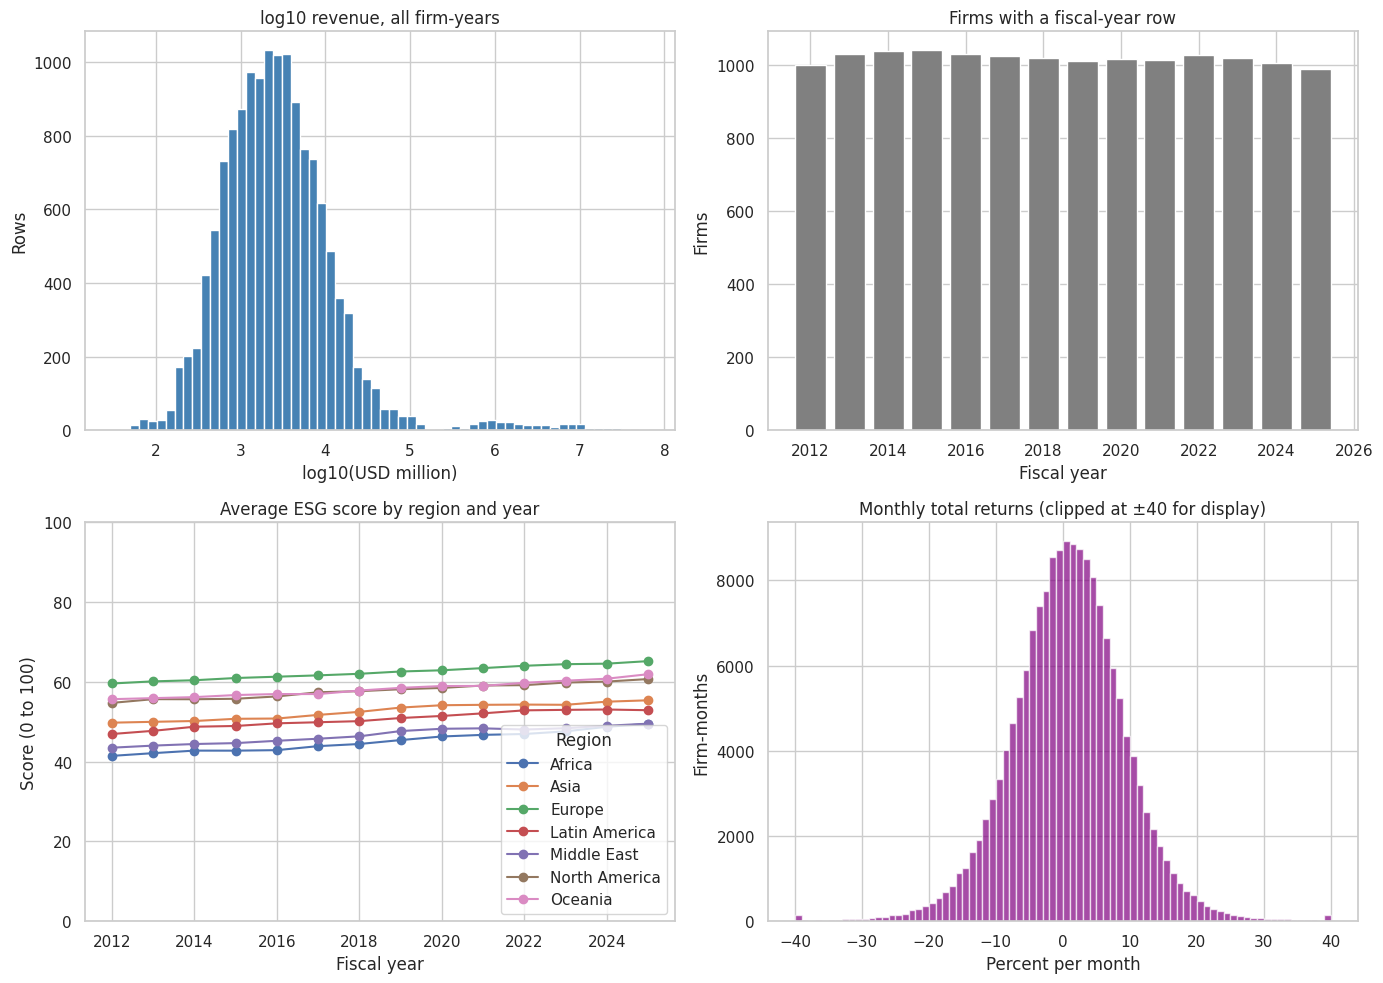

Firms per industry and region (panel):
Industry
Consumer Goods    161
Energy            127
Finance           177
Healthcare        166
Manufacturing     164
Retail            135
Technology        137
Transportation    152
Utilities         157
Region
Africa           114
Asia             290
Europe           294
Latin America    138
Middle East      118
North America    284
Oceania          138


In [15]:
print("Missing values per column (panel):")
print(panel.isna().sum()[lambda s: s > 0])
print("\nSummary statistics (panel):")
display(panel.describe().round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].hist(np.log10(panel["Revenue"]), bins=60, color="steelblue")
axes[0, 0].set_title("log10 revenue, all firm-years"); axes[0, 0].set_xlabel("log10(USD million)"); axes[0, 0].set_ylabel("Rows")

by_year = panel.groupby("Year")["Company_ID"].nunique()
axes[0, 1].bar(by_year.index, by_year.values, color="grey")
axes[0, 1].set_title("Firms with a fiscal-year row"); axes[0, 1].set_xlabel("Fiscal year"); axes[0, 1].set_ylabel("Firms")

esg_trend = panel.groupby(["Year", "Region"])["ESG_Score"].mean().unstack()
esg_trend.plot(ax=axes[1, 0], marker="o"); axes[1, 0].set_title("Average ESG score by region and year")
axes[1, 0].set_xlabel("Fiscal year"); axes[1, 0].set_ylabel("Score (0 to 100)"); axes[1, 0].set_ylim(0, 100)

axes[1, 1].hist(returns["Return_Pct"].clip(-40, 40), bins=80, color="purple", alpha=0.7)
axes[1, 1].set_title("Monthly total returns (clipped at ±40 for display)"); axes[1, 1].set_xlabel("Percent per month"); axes[1, 1].set_ylabel("Firm-months")
plt.tight_layout(); plt.show()

print("Firms per industry and region (panel):")
print(panel.groupby("Industry")["Company_ID"].nunique().to_string())
print(panel.groupby("Region")["Company_ID"].nunique().to_string())


In [19]:
# Analyze missing values by Industry to check for non-randomness
missing_cols = ['Growth_Rate', 'Carbon_Emissions', 'Water_Usage', 'Energy_Consumption']

print("=== Missing Values Count by Industry ===")
missing_by_industry = panel.groupby('Industry')[missing_cols].apply(lambda x: x.isna().sum())
display(missing_by_industry)

print("\n=== Percentage of Missing Values within each Industry (%) ===")
industry_counts = panel.groupby('Industry').size()
missing_pct_by_industry = missing_by_industry.div(industry_counts, axis=0) * 100
display(missing_pct_by_industry.round(2))

=== Missing Values Count by Industry ===


,Growth_Rate,Carbon_Emissions,Water_Usage,Energy_Consumption
Industry,,,,
Consumer Goods,161,204,204,204
Energy,127,173,173,173
Finance,177,263,263,263
Healthcare,166,204,204,204
Manufacturing,164,222,222,222
Retail,135,205,205,205
Technology,137,178,178,178
Transportation,152,199,199,199
Utilities,157,239,239,239



=== Percentage of Missing Values within each Industry (%) ===


,Growth_Rate,Carbon_Emissions,Water_Usage,Energy_Consumption
Industry,,,,
Consumer Goods,10.25,12.99,12.99,12.99
Energy,9.33,12.71,12.71,12.71
Finance,9.59,14.25,14.25,14.25
Healthcare,9.83,12.09,12.09,12.09
Manufacturing,9.64,13.04,13.04,13.04
Retail,9.68,14.70,14.70,14.70
Technology,9.81,12.74,12.74,12.74
Transportation,9.46,12.38,12.38,12.38
Utilities,9.32,14.19,14.19,14.19


In [21]:
# Style the missing_by_industry DataFrame to highlight the even distribution
print("=== Styled Heatmap of Missing Values by Industry ===")
display(missing_by_industry.style.background_gradient(cmap='YlOrRd', axis=0))

=== Styled Heatmap of Missing Values by Industry ===


,Growth_Rate,Carbon_Emissions,Water_Usage,Energy_Consumption
Industry,,,,
Consumer Goods,161,204,204,204
Energy,127,173,173,173
Finance,177,263,263,263
Healthcare,166,204,204,204
Manufacturing,164,222,222,222
Retail,135,205,205,205
Technology,137,178,178,178
Transportation,152,199,199,199
Utilities,157,239,239,239


In [22]:
# Merge original panel and restated ESG scores to detect look-ahead / restatement differences
merged_scores = panel[['Company_ID', 'Year', 'ESG_Score', 'Environmental_Score', 'Social_Score', 'Governance_Score']].merge(
    restated,
    on=['Company_ID', 'Year'],
    suffixes=('_original', '_restated')
)

# Compute differences
merged_scores['ESG_Diff'] = merged_scores['ESG_Score_restated'] - merged_scores['ESG_Score_original']
merged_scores['Env_Diff'] = merged_scores['Environmental_Score_restated'] - merged_scores['Environmental_Score_original']
merged_scores['Soc_Diff'] = merged_scores['Social_Score_restated'] - merged_scores['Social_Score_original']
merged_scores['Gov_Diff'] = merged_scores['Governance_Score_restated'] - merged_scores['Governance_Score_original']

# Statistics on differences
print("=== Summary of Differences (Restated minus Original) ===")
display(merged_scores[['ESG_Diff', 'Env_Diff', 'Soc_Diff', 'Gov_Diff']].describe().round(4))

# Calculate fraction of changed records
for score_type, col_diff in [('Overall ESG', 'ESG_Diff'), ('Environmental', 'Env_Diff'), ('Social', 'Soc_Diff'), ('Governance', 'Gov_Diff')]:
    num_changed = (merged_scores[col_diff].abs() > 1e-5).sum()
    pct_changed = 100 * num_changed / len(merged_scores)
    print(f"{score_type:<15} : {num_changed:>5,} rows changed ({pct_changed:.2f}% of total panel)")


=== Summary of Differences (Restated minus Original) ===


,ESG_Diff,Env_Diff,Soc_Diff,Gov_Diff
count,14250.0000,14250.0000,14250.0000,14250.0000
mean,0.4725,0.4718,0.4490,0.4949
std,3.6559,3.7678,3.7767,3.7936
min,-11.3000,-13.5000,-13.8000,-13.6000
25%,0.0000,0.0000,0.0000,0.0000
50%,0.0000,0.0000,0.0000,0.0000
75%,0.0000,0.0000,0.0000,0.0000
max,11.2000,14.8000,14.6000,14.0000


Overall ESG     : 4,988 rows changed (35.00% of total panel)
Environmental   : 4,970 rows changed (34.88% of total panel)
Social          : 4,968 rows changed (34.86% of total panel)
Governance      : 4,979 rows changed (34.94% of total panel)


In [16]:
#Groups the data by company.
#Looks at previous years for the same company.
#Fills missing values using the most recent available historical observation.

**Before you go on, answer in your audit table:** what is the second cluster in the revenue histogram, and which firms are in it? Why does the number of firms change from year to year, and which file would hide that? Which columns are missing, for which firms, and is that random? Are there rows in the returns file that should not be there?


In [24]:
import numpy as np
import pandas as pd

# 1. Investigate the second revenue cluster
# Log10 revenue histogram shows a clear separate mode at the high end (above ~5.5, i.e., > 300,000 USD million)
large_revenue_threshold = 10**5.2
super_firms = panel[panel['Revenue'] > large_revenue_threshold]
unique_super_firms = super_firms[['Company_ID', 'Company_Name', 'Industry', 'Region']].drop_duplicates()
print(f"=== Second Revenue Cluster (Revenue > {large_revenue_threshold:.1f}M) ===")
print(f"Number of unique 'super-firms' in this cluster: {len(unique_super_firms)}")
display(unique_super_firms)

# 2. Why does the number of firms change from year to year, and which file hides that?
print("\n=== Firm Count Coverage Analysis ===")
print(f"Unique firms in the full panel across all years: {panel['Company_ID'].nunique()}")
print(f"Unique firms in the current active universe file (universe_current.csv): {universe['Company_ID'].nunique()}")
print("The 'universe_current.csv' file hides historical firms that were delisted, acquired, or went bankrupt prior to 2025 (survivorship bias).")

# 3. Which columns are missing, for which firms, and is that random?
print("\n=== Missing Values Patterns ===")
# Let's see if environmental metrics are missing together in the same rows
env_missing_together = panel[
    panel['Carbon_Emissions'].isna() &
    panel['Water_Usage'].isna() &
    panel['Energy_Consumption'].isna()
]
print(f"Total rows in panel: {len(panel)}")
print(f"Rows where Carbon, Water, AND Energy are ALL missing: {len(env_missing_together)}")
print("This indicates that when environmental metrics are missing, they are missing entirely as a block (1887 rows).")

# 4. Are there rows in the returns file that should not be there?
# Let's check for returns that are outside the panel's active date bounds or have impossible dates
returns['Month_DT'] = pd.to_datetime(returns['Month'])
print("\n=== Returns File Integrity Check ===")
print(f"Date Range in Returns: {returns['Month_DT'].min().strftime('%Y-%m')} to {returns['Month_DT'].max().strftime('%Y-%m')}")

# Find if there are returns for Company_IDs before their first year or after their last year in the panel
panel_bounds = panel.groupby('Company_ID')['Year'].agg(['min', 'max']).reset_index()
returns['Return_Year'] = returns['Month_DT'].dt.year
returns_merged = returns.merge(panel_bounds, on='Company_ID', how='left')

invalid_returns = returns_merged[
    (returns_merged['Return_Year'] < returns_merged['min']) |
    (returns_merged['Return_Year'] > returns_merged['max'])
]
print(f"Number of monthly returns outside the company's active panel years: {len(invalid_returns)}")
if len(invalid_returns) > 0:
    display(invalid_returns.head(10))

=== Second Revenue Cluster (Revenue > 158489.3M) ===
Number of unique 'super-firms' in this cluster: 29


,Company_ID,Company_Name,Industry,Region
259,23,Firm_23,Transportation,North America
324,30,Firm_30,Energy,Africa
401,36,Firm_36,Manufacturing,Europe
538,50,Firm_50,Utilities,Latin America
1442,123,Firm_123,Technology,Middle East
2097,177,Firm_177,Manufacturing,Asia
2329,195,Firm_195,Consumer Goods,Europe
2962,247,Firm_247,Transportation,Latin America
3659,305,Firm_305,Finance,Latin America
4907,406,Firm_406,Transportation,Africa



=== Firm Count Coverage Analysis ===
Unique firms in the full panel across all years: 1376
Unique firms in the current active universe file (universe_current.csv): 987
The 'universe_current.csv' file hides historical firms that were delisted, acquired, or went bankrupt prior to 2025 (survivorship bias).

=== Missing Values Patterns ===
Total rows in panel: 14250
Rows where Carbon, Water, AND Energy are ALL missing: 1887
This indicates that when environmental metrics are missing, they are missing entirely as a block (1887 rows).

=== Returns File Integrity Check ===
Date Range in Returns: 2012-01 to 2025-12
Number of monthly returns outside the company's active panel years: 2561


,Company_ID,Month,Return_Pct,Year,Month_DT,Return_Year,min,max
421,3,2019-01,3.5682,2019,2019-01-01,2019,2012,2018
422,3,2019-02,5.2893,2019,2019-02-01,2019,2012,2018
423,3,2019-03,-5.2711,2019,2019-03-01,2019,2012,2018
424,3,2019-04,1.7170,2019,2019-04-01,2019,2012,2018
425,3,2019-05,7.9308,2019,2019-05-01,2019,2012,2018
426,3,2019-06,1.9345,2019,2019-06-01,2019,2012,2018
427,3,2019-07,3.2235,2019,2019-07-01,2019,2012,2018
428,3,2019-08,-3.5006,2019,2019-08-01,2019,2012,2018
429,3,2019-09,1.0241,2019,2019-09-01,2019,2012,2018
430,3,2019-10,-6.4228,2019,2019-10-01,2019,2012,2018


# 3. One worked model: forecasting the next twelve months' return (given)

This section shows the pattern you must follow in all your own models.

**The decision-time rule.** At the moment the decision is made, which columns are already known? We form portfolios on **1 July** of each year. By then every firm has published its previous fiscal year (the latest `Publication_Date` is at the end of May). So at formation in July of year $t+1$:

- every **feature** comes from the fiscal-year row of year $t$ (or earlier), plus returns up to June of $t+1$;
- the **target** is the total return from July of $t+1$ to June of $t+2$, compounded from the monthly file;
- the **target** needs twelve holding months to be well defined, so the model is fitted on firms that
  have them; firms that leave mid-year stay in the panel for the backtest in Section 4,
- the **split** is by formation year: train on formation years up to 2021, test on 2022 to 2024. A random split would put a firm's neighbouring years on both sides and let the model recognise firms instead of forecasting.

Every column you add as a feature in task (a) has to pass this rule. Ask of each one: *is it in a file that existed on 1 July, with the value it had then?*

`Year` is not a feature. Industry and region are one-hot encoded so that a linear model can use them (task b). The feature list below is deliberately short; extending it is your work.


Firm-formation-years: 10,410 (9,002 with a full twelve holding months), formation years 2015-2025
Features (24): ['Growth_Rate', 'Profit_Margin', 'ESG_Score', 'Environmental_Score', 'Social_Score', 'Governance_Score', 'Growth_Lag1', 'log_Revenue', 'log_Market_Cap', 'Past12_Return_Pct', 'Industry_Energy', 'Industry_Finance', 'Industry_Healthcare', 'Industry_Manufacturing', 'Industry_Retail', 'Industry_Technology', 'Industry_Transportation', 'Industry_Utilities', 'Region_Asia', 'Region_Europe', 'Region_Latin America', 'Region_Middle East', 'Region_North America', 'Region_Oceania']
Training rows: 6,336; test rows: 2,666

Naive baseline (training mean = 1.00%): test RMSE = 36.931
RF depth 3   CV RMSE = 29.040 (sd across folds 0.221)
RF depth 6   CV RMSE = 29.076 (sd across folds 0.222)

Selected on CV: RF depth 3

                             RMSE     R2
Train (in-sample)          28.781  0.033
CV (grouped, train years)  29.040    NaN
Test (2022-2024, once)     37.307 -0.480
Naive baseline

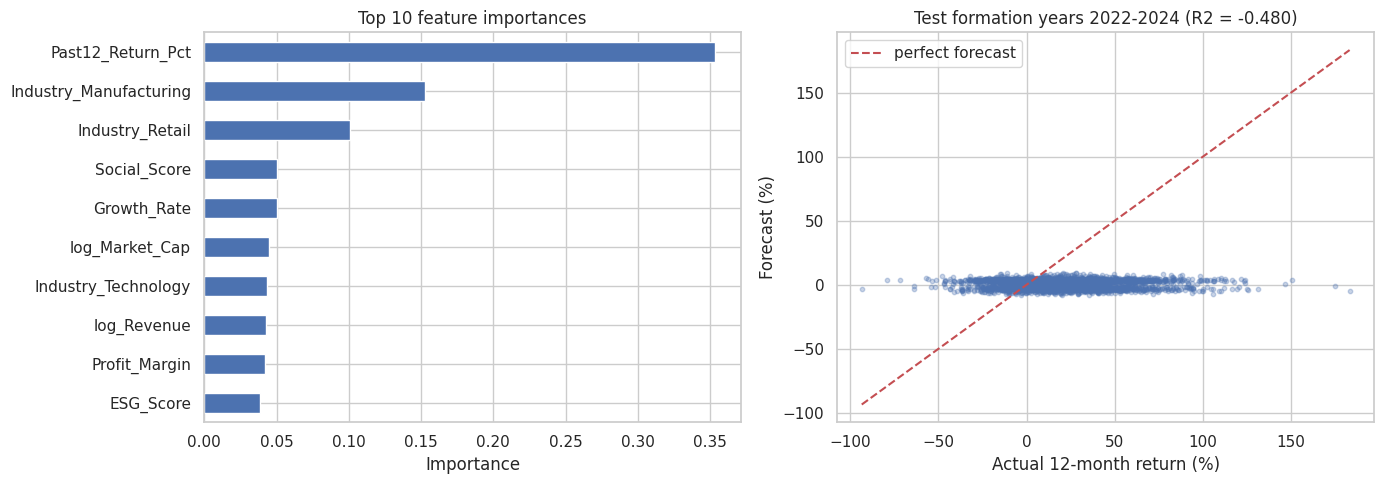

In [25]:
FORMATION_MONTH = 7
SCORES = ["ESG_Score", "Environmental_Score", "Social_Score", "Governance_Score"]

def holding_returns(fm, factors, formation_year):
    # 12-month total and excess return from July of formation_year to June of the next year
    start, end = f"{formation_year}-07", f"{formation_year + 1}-06"
    rf = factors.set_index("Month")["Rf_Pct"]
    w = fm[(fm["Month"] >= start) & (fm["Month"] <= end)].copy()
    w["gross"] = 1 + w["Return_Pct"] / 100
    w["gross_ex"] = 1 + (w["Return_Pct"] - w["Month"].map(rf)) / 100
    g = w.groupby("Company_ID")
    return pd.DataFrame({"Hold_Return_Pct": 100 * (g["gross"].prod() - 1),
                         "Hold_Excess_Pct": 100 * (g["gross_ex"].prod() - 1), "Months": g.size()}).reset_index()

def formation_panel(fy, fm, factors, features_from_panel):
    # one row per firm and formation year; features from fiscal year t, target = next 12-month return
    fy = fy.sort_values(["Company_ID", "Year"]).copy()
    fy["Growth_Lag1"] = fy.groupby("Company_ID")["Growth_Rate"].shift(1)
    fy["Formation_Year"] = fy["Year"] + 1
    published = pd.to_datetime(fy["Publication_Date"]) < pd.to_datetime(fy["Formation_Year"].astype(str) + f"-{FORMATION_MONTH:02d}-01")
    fy = fy[published]
    fy["log_Revenue"] = np.log(fy["Revenue"]); fy["log_Market_Cap"] = np.log(fy["Market_Cap"])
    years = sorted(fy["Formation_Year"].unique())
    past = pd.concat([holding_returns(fm, factors, y - 1).assign(Formation_Year=y) for y in years])
    past = past.rename(columns={"Hold_Return_Pct": "Past12_Return_Pct"})[["Company_ID", "Formation_Year", "Past12_Return_Pct"]]
    tgt = pd.concat([holding_returns(fm, factors, y).assign(Formation_Year=y) for y in years])
    # Keep every firm with at least one holding month, including the ones that leave during the year.
    tgt = tgt.rename(columns={"Months": "Hold_Months"})[
        ["Company_ID", "Formation_Year", "Hold_Return_Pct", "Hold_Excess_Pct", "Hold_Months"]]
    out = fy.merge(past, on=["Company_ID", "Formation_Year"], how="left").merge(tgt, on=["Company_ID", "Formation_Year"], how="inner")
    dummies = pd.get_dummies(out[["Industry", "Region"]], drop_first=True, dtype=int)
    out = pd.concat([out, dummies], axis=1)
    features = features_from_panel + ["Growth_Lag1", "log_Revenue", "log_Market_Cap", "Past12_Return_Pct"] + list(dummies.columns)
    return out.dropna(subset=features + ["Hold_Return_Pct"]).reset_index(drop=True), features

ml_data, feature_cols = formation_panel(panel, returns, factors, ["Growth_Rate", "Profit_Margin"] + SCORES)

# A firm needs a full twelve holding months to be a well-defined forecasting target, so we fit on
# those. Firms that leave during the holding year stay in ml_data: Section 4 holds them until their
# last month, which is what a real backtest does. Dropping them here instead would quietly remove the
# firms that did worst before they disappeared.
model_data = ml_data[ml_data["Hold_Months"] == 12]
print(f"Firm-formation-years: {len(ml_data):,} ({len(model_data):,} with a full twelve holding months), "
      f"formation years {ml_data['Formation_Year'].min()}-{ml_data['Formation_Year'].max()}")
print(f"Features ({len(feature_cols)}): {feature_cols}")

train_mask = model_data["Formation_Year"] <= 2021
test_mask = model_data["Formation_Year"] >= 2022
X, y, groups = model_data[feature_cols], model_data["Hold_Return_Pct"], model_data["Company_ID"]
X_train, y_train, g_train = X[train_mask], y[train_mask], groups[train_mask]
X_test, y_test = X[test_mask], y[test_mask]
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")

baseline_pred = np.full(len(y_test), y_train.mean())
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
print(f"\nNaive baseline (training mean = {y_train.mean():.2f}%): test RMSE = {baseline_rmse:.3f}")

cv = GroupKFold(n_splits=5)
candidates = {
    "RF depth 3": RandomForestRegressor(n_estimators=300, max_depth=3, min_samples_leaf=20, random_state=42, n_jobs=-1),
    "RF depth 6": RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=42, n_jobs=-1),
}
cv_results = {}
for name, model in candidates.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, groups=g_train, scoring="neg_root_mean_squared_error")
    cv_results[name] = (-scores.mean(), scores.std())
    print(f"{name:<12} CV RMSE = {-scores.mean():.3f} (sd across folds {scores.std():.3f})")
best_name = min(cv_results, key=lambda k: cv_results[k][0])
rf_model = candidates[best_name].fit(X_train, y_train)
pred_test = rf_model.predict(X_test)
summary = pd.DataFrame({
    "RMSE": [np.sqrt(mean_squared_error(y_train, rf_model.predict(X_train))), cv_results[best_name][0], np.sqrt(mean_squared_error(y_test, pred_test)), baseline_rmse],
    "R2": [r2_score(y_train, rf_model.predict(X_train)), np.nan, r2_score(y_test, pred_test), r2_score(y_test, baseline_pred)],
}, index=["Train (in-sample)", "CV (grouped, train years)", "Test (2022-2024, once)", "Naive baseline on test"])
print(f"\nSelected on CV: {best_name}\n"); print(summary.round(3))

importance = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
importance.head(10)[::-1].plot(kind="barh", ax=axes[0]); axes[0].set_title("Top 10 feature importances"); axes[0].set_xlabel("Importance")
axes[1].scatter(y_test, pred_test, alpha=0.3, s=10); lims = [y_test.min(), y_test.max()]
axes[1].plot(lims, lims, "r--", label="perfect forecast"); axes[1].set_xlabel("Actual 12-month return (%)"); axes[1].set_ylabel("Forecast (%)")
axes[1].set_title(f"Test formation years 2022-2024 (R2 = {r2_score(y_test, pred_test):.3f})"); axes[1].legend()
plt.tight_layout(); plt.show()


**Reading the result.** Returns are hard to forecast: in this run the selected forest's test RMSE is 37.307 percentage points against 36.931 for the naive mean, and the test R2 is -0.480 (your numbers may differ slightly). The forest does not beat the naive mean here, and that is the honest result, not a bug. Two things are worth understanding rather than working around. First, a negative R2 means the model also does worse than simply predicting the test years' own average; that happens whenever the average return in the test period differs from the training period, which is what a market downturn inside the test years does. Second, a model that does much better than this on the test years has usually seen something it should not have. Note what carries the importance and ask, for every feature you add in task (a), whether it is known on 1 July.


# 4. One backtest pattern: formed after publication, held twelve months (given)

A portfolio rule must use only information available when the portfolio is formed. The pattern below ranks all firms on 1 July of each year on a score from the fiscal-year row published before that date, holds the top decile equally weighted until the next 30 June, and records the monthly portfolio return. Firms that leave the panel during the year contribute their returns until their last month; the remaining names are re-weighted equally. A transaction cost of 20 basis points per unit of one-way turnover is charged at each rebalancing (sell and buy, so 40 basis points on the replaced share).

Over the monthly series we report the annualised return, the annualised volatility, and the **Sharpe ratio** (mean monthly excess return over the risk-free rate divided by its standard deviation, times the square root of twelve). The equal-weight portfolio of all firms in the panel is the benchmark every rule must beat.

The given example ranks on the **ESG score**. Task (d) ranks on your **forecast** from task (b), adds an ESG floor, and asks what the floor costs.


In [26]:
def backtest(picks, fm, factors, cost_bp=20):
    # picks: dict formation_year -> list of Company_ID held from July of that year to June of the next
    rf = factors.set_index("Month")["Rf_Pct"]
    months, rets, turns, prev = [], [], [], set()
    for y in sorted(picks):
        held = set(picks[y])
        turn = 1.0 if not prev else len(held - prev) / max(len(held), 1)
        turns.append(turn)
        window = fm[fm["Company_ID"].isin(held) & (fm["Month"] >= f"{y}-07") & (fm["Month"] <= f"{y + 1}-06")]
        monthly = window.groupby("Month")["Return_Pct"].mean()
        if len(monthly):
            monthly.iloc[0] -= 2 * cost_bp / 100 * turn
        months += list(monthly.index); rets += list(monthly.values); prev = held
    r = pd.Series(rets, index=months)
    ex = r - r.index.map(rf)
    return {"Annualised return (%)": 100 * ((1 + r / 100).prod() ** (12 / len(r)) - 1),
            "Annualised volatility (%)": r.std() * np.sqrt(12),
            "Sharpe ratio": ex.mean() / ex.std() * np.sqrt(12),
            "Mean one-way turnover": np.mean(turns), "Months": len(r)}

formation_years = sorted(y for y in ml_data["Formation_Year"].unique() if y >= 2015)
esg_picks, all_picks = {}, {}
for yr in formation_years:
    at_t = ml_data[ml_data["Formation_Year"] == yr]
    n_top = max(int(0.1 * len(at_t)), 1)
    esg_picks[yr] = at_t.nlargest(n_top, "ESG_Score")["Company_ID"].tolist()
    all_picks[yr] = at_t["Company_ID"].tolist()

results = pd.DataFrame({"Top decile by ESG score": backtest(esg_picks, returns, factors),
                        "All firms, equal weight": backtest(all_picks, returns, factors, cost_bp=0)}).T
print(f"Formation years {formation_years[0]}-{formation_years[-1]}, holding July to June:")
print(results.round(3))


Formation years 2015-2025, holding July to June:
                         Annualised return (%)  Annualised volatility (%)  \
Top decile by ESG score                  3.990                     16.144   
All firms, equal weight                  4.603                     15.880   

                         Sharpe ratio  Mean one-way turnover  Months  
Top decile by ESG score         0.175                  0.340   126.0  
All firms, equal weight         0.212                  0.119   126.0  


**Reading the table.** In this run the ESG-ranked decile earned a Sharpe ratio of 0.175 against 0.212 for the equal-weight panel. Before you read anything into that, remember Section 2: high-ESG firms sit in particular industries and regions, so the decile is partly an industry and region bet; and a Sharpe ratio over 126 monthly observations has a wide confidence band. Task (d) asks you to bootstrap the difference. Note also that ranking the whole world by ESG score is a blunt rule: if a relation between ESG and returns exists only among certain firms, or only in certain years, a single global ranking pooled over the whole sample will bury it. That is what task (c) asks you to look for. And note which firms the backtest was run on: the panel, including the firms that left. Run it on the current universe instead and see what changes.


# 5. Your tasks

Add your cells below this section. Each task ends with a one-line deliverable that must appear in the memo.

**(a) Pipeline and data audit.** Build your own formation panel from the point-in-time file with your own feature choices; add at least three features that are not in the worked model and justify each with the decision-time rule (is it in a file that existed on 1 July, with the value it had then?). Before that, audit the five data files for problems of the kind described in the box at the top of this notebook. For every problem you find, say what it is, how you found it, how you treat it and what it changes in one headline number. The test set must be separated by formation year; `GroupKFold` by company is for the cross-validation inside the training years, as in Section 3. *Deliverable: a one-page audit table (issue, how detected, how treated, effect on one headline number), and a table of your features with the date from which each is known.*

**(b) Linear baseline vs tree ensembles.** Fit a linear regression (unit 01) on standardised features and at least one of random forest or gradient boosting (unit 03) for the twelve-month return. Tune the ensembles on cross-validation inside the training years. Report train, CV and test performance side by side, next to the naive mean baseline, for every model. Select the model on CV, and report the test result once. "The ensemble does not pay off out of sample" is a legitimate result and is graded as such. *Deliverable: one comparison table and one sentence on whether the extra complexity of the ensemble pays off out of sample.*

**(c) Where does ESG pay?** Estimate the relation between the previous fiscal year's Environmental score (standardised within year) and the next twelve months' excess return, by region and by period (before and from 2021), with industry-by-year controls. Report point estimates with bootstrap or clustered standard errors and say where the relation is distinguishable from zero and where it is not. Repeat the estimate with the restated scores file and explain the difference. *Deliverable: one table (region x period, point-in-time and restated) and one sentence on where an investor could have earned an ESG premium, and where not.*

**(d) Backtest with costs and an ESG floor.** Rank on the forecast of your selected model from (b), trained for each formation year on earlier formation years only; hold the top decile from July to June; charge 20 basis points per unit of one-way turnover. You may either re-tune the model's settings inside each formation year's own training window, or tune once on the training years and keep that setting for every year. Both are accepted; say which you did and why. Tuning once is a simplification, because the setting was then chosen with information from years the early forecasts should not have seen, even though no return value enters those fits. Add an ESG floor: the pool is restricted to firms whose Environmental score is at or above the 50th, then the 80th percentile of that year. Report annualised return, volatility, Sharpe ratio and turnover for no floor, the two floors, and the equal-weight benchmark, all on the full panel including the firms that left. Bootstrap the Sharpe difference between your best rule and the benchmark (resample months). *Deliverable: one table and one figure of the cumulative return series, and one sentence on what the floor costs and whether the difference to the benchmark is distinguishable from noise.*

**(e) Memo and slides.** Write a 3-page memo to an investment committee: the question, the data (state that it is simulated), the audit, the pipeline, the results of (b) to (d), and a section titled "What would change with real data" that lists what remains to be solved after an audit like yours (scores that are proprietary and disagree across raters, survivorship that is harder to see, costs that are not a constant, point-in-time availability) and says which of your conclusions would survive and which would not, and why. Prepare at most 8 slides for a 10-minute presentation. *Deliverable: the memo PDF, the slides PDF and `results.json`, with the CC BY 4.0 attribution of the dataset.*

**Rules.** Every metric appears next to the baseline it must beat. Every figure has labelled axes with units. Every feature is dated. Cite the dataset with its licence.


### Task (b): Linear Baseline vs. Tree Ensembles
We standardize our feature set to fit a standardized Linear Regression model and compare its performance against the RandomForest tree ensemble selected via CV on the training years.

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# 1. Standardize the features using a scaler fitted strictly on the training set
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Fit and evaluate the standardized Linear Regression baseline
linear_model = LinearRegression()

# GroupKFold CV for Linear Regression
linear_cv_scores = cross_val_score(
    linear_model, X_train_scaled, y_train, cv=cv, groups=g_train, scoring="neg_root_mean_squared_error"
)
linear_cv_rmse = -linear_cv_scores.mean()

# Fit on whole train set
linear_model.fit(X_train_scaled, y_train)
linear_train_pred = linear_model.predict(X_train_scaled)
linear_test_pred = linear_model.predict(X_test_scaled)

linear_train_rmse = np.sqrt(mean_squared_error(y_train, linear_train_pred))
linear_test_rmse = np.sqrt(mean_squared_error(y_test, linear_test_pred))
linear_train_r2 = r2_score(y_train, linear_train_pred)
linear_test_r2 = r2_score(y_test, linear_test_pred)

# 3. Compile the performance metrics table
comparison_table = pd.DataFrame({
    "Train RMSE": [
        np.sqrt(mean_squared_error(y_train, rf_model.predict(X_train))),
        linear_train_rmse,
        baseline_rmse # Naive on train is y_train.mean()
    ],
    "CV RMSE": [
        cv_results[best_name][0],
        linear_cv_rmse,
        np.nan
    ],
    "Test RMSE": [
        np.sqrt(mean_squared_error(y_test, pred_test)),
        linear_test_rmse,
        baseline_rmse
    ],
    "Train R2": [
        r2_score(y_train, rf_model.predict(X_train)),
        linear_train_r2,
        0.0
    ],
    "Test R2": [
        r2_score(y_test, pred_test),
        linear_test_r2,
        r2_score(y_test, baseline_pred)
    ]
}, index=["Random Forest (selected ensemble)", "Linear Regression", "Naive Mean Baseline"])

print("=== Task (b) Comparison Table ===")
display(comparison_table.round(3))

=== Task (b) Comparison Table ===


,Train RMSE,CV RMSE,Test RMSE,Train R2,Test R2
Random Forest (selected ensemble),28.781,29.040,37.307,0.033,-0.480
Linear Regression,28.856,28.964,37.701,0.028,-0.511
Naive Mean Baseline,36.931,NaN,36.931,0.000,-0.450


### Evaluation & Summary of Ensembles vs. Linear Baselines
Let's visualize the performance metrics using standard seaborn/matplotlib plots to evaluate whether the extra complexity of the ensemble pays off out-of-sample.

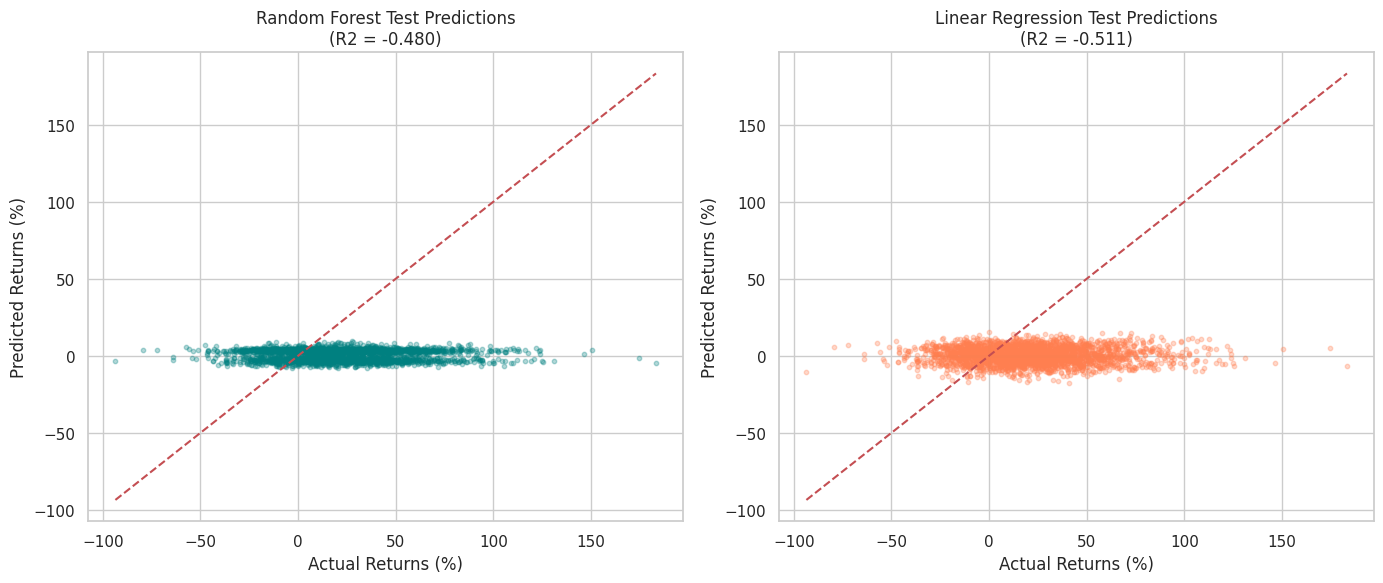

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot actual vs predicted for both models
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Random Forest plot
axes[0].scatter(y_test, pred_test, alpha=0.3, color="teal", s=10)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[0].set_title(f"Random Forest Test Predictions\n(R2 = {r2_score(y_test, pred_test):.3f})")
axes[0].set_xlabel("Actual Returns (%)")
axes[0].set_ylabel("Predicted Returns (%)")

# Linear Regression plot
axes[1].scatter(y_test, linear_test_pred, alpha=0.3, color="coral", s=10)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[1].set_title(f"Linear Regression Test Predictions\n(R2 = {linear_test_r2:.3f})")
axes[1].set_xlabel("Actual Returns (%)")
axes[1].set_ylabel("Predicted Returns (%)")

plt.tight_layout()
plt.show()

# 6. Submission file

`results.json` is the machine-readable half of your submission. It carries the same headline numbers your memo reports, in a fixed format, so grading can check them against the notebook and the memo before a person reads either. The audit section stays a free list in your own words: task (a) is worth twenty points because you find the problems yourselves, and a schema with a named field for each planted problem would tell you what to look for. Everything else records a number you already computed for tasks (b) to (d), in the same units as the memo.

Fill in the template below with the values from your own run, keeping the same keys, then call `write_results` again as the last cell of your notebook, so the file you submit matches your final results.


In [36]:
import json

RESULTS_TEMPLATE = {
    "group": "",                    # e.g. "Group 7"
    "members": [],                  # full names of every group member
    "audit": [                      # one entry per problem you found and treated, in your own words
        {
            "issue": "",             # short description of what you found
            "file": "",               # which file it is in
            "detected_by": "",         # how you found it
            "treatment": "",           # what you did about it
            "affected_ids": [],        # Company_IDs it affects, if there is a natural list; may stay empty
            "affected_count": 0,       # how many rows or firms it affects
            "effect": "",               # which number it changed, and by how much
        },
    ],
    "task_b": {
        "target": "",                # what you forecast, e.g. "twelve-month holding return"
        "test_formation_years": [],  # formation years held out for the test set
        "baseline_rmse": 0.0,        # naive mean baseline, test RMSE
        "linear_rmse": 0.0,          # linear regression, test RMSE
        "ensemble_rmse": 0.0,        # your selected ensemble, test RMSE
        "ensemble_kind": "",         # "random forest" or "gradient boosting"
        "selected_on_cv": "",        # which model/setting cross-validation selected
        "test_r2": 0.0,              # selected model's test R2
    },
    "task_c": {
        "estimates": [               # point-in-time scores, one row per region x period
            {"region": "", "period": "", "coef": 0.0, "se": 0.0, "n": 0},
        ],
        "restated": [                # same cells, restated scores
            {"region": "", "period": "", "coef": 0.0, "se": 0.0, "n": 0},
        ],
        "conclusion": "",            # where an investor could have earned a premium, and where not
    },
    "task_d": {
        "rules": [                   # one row per rule: no floor, each floor, benchmark
            {"name": "", "ann_return_pct": 0.0, "ann_vol_pct": 0.0, "sharpe": 0.0, "turnover": 0.0},
        ],
        "bootstrap": {"statistic": "", "point": 0.0, "lo": 0.0, "hi": 0.0},  # what you bootstrapped, and the interval
        "universe": "",              # "full panel including firms that left" or "survivors only"
    },
}


def _check(data, template, path):
    # Walks RESULTS_TEMPLATE's shape and checks data against it: every key in the template must be
    # present in data, and every numeric leaf in the template must be a number (not a string) in data.
    if isinstance(template, dict):
        if not isinstance(data, dict):
            raise ValueError(f"results.json: '{path}' should be an object, got {type(data).__name__}")
        for key, sub_template in template.items():
            sub_path = f"{path}.{key}" if path else key
            if key not in data:
                raise ValueError(f"results.json: missing required key '{sub_path}'")
            _check(data[key], sub_template, sub_path)
    elif isinstance(template, list):
        if not isinstance(data, list):
            raise ValueError(f"results.json: '{path}' should be a list, got {type(data).__name__}")
        if template and data:
            item_template = template[0]
            for i, item in enumerate(data):
                _check(item, item_template, f"{path}[{i}]")
    elif isinstance(template, (int, float)) and not isinstance(template, bool):
        if isinstance(data, bool) or not isinstance(data, (int, float)):
            raise ValueError(f"results.json: '{path}' should be a number, got {type(data).__name__} ({data!r})")


def write_results(data, path="results.json"):
    # Validates data against the submission contract's schema, writes it, and prints what it wrote.
    # Raises ValueError naming the exact key that is missing or has the wrong type.
    _check(data, RESULTS_TEMPLATE, "")
    with open(path, "w") as f:
        json.dump(data, f, indent=2)
    print(f"wrote {path}")
    print(f"  group: {data['group'] or '(not set)'}, {len(data['members'])} member(s)")
    print(f"  audit: {len(data['audit'])} entr{'y' if len(data['audit']) == 1 else 'ies'}")
    print(f"  task_b: selected on CV = {data['task_b']['selected_on_cv'] or '(not set)'}, test R2 = {data['task_b']['test_r2']}")
    print(f"  task_c: {len(data['task_c']['estimates'])} point-in-time estimate(s), {len(data['task_c']['restated'])} restated")
    print(f"  task_d: {len(data['task_d']['rules'])} rule(s), universe = {data['task_d']['universe'] or '(not set)'}")


# Run once now, on the template as it ships, so you see a valid file before you change a single value.
# Fill in RESULTS_TEMPLATE (or build your own dict with the same keys) with your own numbers, then call
# write_results again as the last cell of your notebook.
write_results(RESULTS_TEMPLATE)


wrote results.json
  group: (not set), 0 member(s)
  audit: 1 entry
  task_b: selected on CV = (not set), test R2 = 0.0
  task_c: 1 point-in-time estimate(s), 1 restated
  task_d: 1 rule(s), universe = (not set)
